# NBA Home-Win Prediction: Status Update
Sections so far: **1. Load data**, **2. The ML problem and project plan**, **3. Data preparation**, **4. Exploratory data analysis**. Models come next.

## 1. Load the data
Kaggle "NBA games data" (Nathan Lauga), five CSV files, seasons 2003-04 to 2022-23.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA = Path("../src/dataset")
files = ["games", "games_details", "ranking", "players", "teams"]
raw = {f: pd.read_csv(DATA / f"{f}.csv", dtype={"LEAGUE_ID": str}, low_memory=False) for f in files}

pd.DataFrame({"rows": {f: len(d) for f, d in raw.items()},
              "columns": {f: d.shape[1] for f, d in raw.items()}})

,rows,columns
games,26651,21
games_details,668628,29
ranking,210342,13
players,7228,4
teams,30,14


In [2]:
raw["games"].head(3)

,GAME_DATE_EST,GAME_ID,GAME_STATUS_TEXT,HOME_TEAM_ID,VISITOR_TEAM_ID,SEASON,TEAM_ID_home,PTS_home,FG_PCT_home,FT_PCT_home,...,AST_home,REB_home,TEAM_ID_away,PTS_away,FG_PCT_away,FT_PCT_away,FG3_PCT_away,AST_away,REB_away,HOME_TEAM_WINS
0,2022-12-22,22200477,Final,1610612740,1610612759,2022,1610612740,126.0,0.484,0.926,...,25.0,46.0,1610612759,117.0,0.478,0.815,0.321,23.0,44.0,1
1,2022-12-22,22200478,Final,1610612762,1610612764,2022,1610612762,120.0,0.488,0.952,...,16.0,40.0,1610612764,112.0,0.561,0.765,0.333,20.0,37.0,1
2,2022-12-21,22200466,Final,1610612739,1610612749,2022,1610612739,114.0,0.482,0.786,...,22.0,37.0,1610612749,106.0,0.470,0.682,0.433,20.0,46.0,1


In [3]:
raw["games"].dtypes.to_frame("dtype").T

,GAME_DATE_EST,GAME_ID,GAME_STATUS_TEXT,HOME_TEAM_ID,VISITOR_TEAM_ID,SEASON,TEAM_ID_home,PTS_home,FG_PCT_home,FT_PCT_home,...,AST_home,REB_home,TEAM_ID_away,PTS_away,FG_PCT_away,FT_PCT_away,FG3_PCT_away,AST_away,REB_away,HOME_TEAM_WINS
dtype,str,int64,str,int64,int64,int64,int64,float64,float64,float64,...,float64,float64,int64,float64,float64,float64,float64,float64,float64,int64


Which files we use:
- **`games.csv`**: one row per game, with the label. This is the base table.
- **`ranking.csv`**: daily standings. This is the one file we merge in.
- `games_details.csv` (player box scores), `players.csv`, `teams.csv`: not used for now.

## 2. The machine learning problem
- **Task:** binary classification. Predict whether the home team wins an NBA game using only information available **before tip-off**.
- **Target:** `HOME_TEAM_WINS` (1 = home team won, 0 = away team won).
- **Baseline to beat:** home teams win about 59% of games, so always guessing "home wins" is already about 59% accurate.
- **Key risk:** the box-score columns in `games.csv` (points, FG%, rebounds, ...) describe the same game, so they give the answer away. Every feature must come from **earlier** games or earlier standings only.

### 2.1 Project plan
**Goal:** predict whether the home team wins using only pre-game information, and beat the 59% "always pick home" baseline.

| Step | What we do | Status |
|---|---|---|
| 1 | Load and clean the data | Done |
| 2 | Merge standings, build pre-game features, drop all IDs | Done |
| 3 | Fixed time-based split (train 2003-2016, validation 2017-18, test 2019-22) | Done |
| 4 | Exploratory data analysis | Done |
| 5 | Baselines and first models | Next |
| 6 | Check fit (over/underfitting), tune, compare | Next |
| 7 | Remaining models, feature importance, final write-up | After Thanksgiving |

**Models**
- *First round:* majority class, Elo only, logistic regression, random forest, gradient boosting, small neural network.
- *Later:* KNN, decision tree, SVM (linear and Gaussian), XGBoost, CatBoost, stacking or voting, and a deeper neural network.

**Evaluation:** accuracy, precision, recall, F1, ROC-AUC and log loss. Tuning uses forward-chaining folds inside the training seasons; the test seasons are used only for the final score.

**Ground rules:** no IDs as inputs, no same-game stats, no shuffling across time.

## 3. Data preparation
### 3.1 Clean `games.csv`

In [4]:
g = raw["games"].copy()
n_start = len(g)

pct = [c for c in g.columns if "PCT" in c]
g[pct] = g[pct].round(3)                          # removes float noise such as 0.34299999

n_dup = int(g["GAME_ID"].duplicated().sum())
g = g.drop_duplicates("GAME_ID")                  # same game written twice (Dec 2020 - Jan 2021); keep the first copy

n_nostats = int(g["PTS_home"].isna().sum())
g = g[g["PTS_home"].notna()]                      # 2003 preseason games with no stats and a placeholder label of 0

is_pre = g["GAME_ID"] // 10_000_000 == 1          # first digit of GAME_ID: 1 = preseason
n_pre = int(is_pre.sum())
g = g[~is_pre]                                    # preseason games are not real results

g["GAME_DATE"] = pd.to_datetime(g["GAME_DATE_EST"])
# the 2020 "bubble" restart: every game was at a neutral site, so "home" is only a label
g["NEUTRAL_SITE"] = (g["SEASON"] == 2019) & (g["GAME_DATE"] >= "2020-07-30")
g = g.sort_values(["GAME_DATE", "GAME_ID"]).reset_index(drop=True)

pd.DataFrame({"games": [n_start, -n_dup, -n_nostats, -n_pre, len(g)]},
             index=["start", "duplicate game ids", "no-stat games", "preseason games", "usable games"])

,games
start,26651
duplicate game ids,-29
no-stat games,-99
preseason games,-1675
usable games,24848


### 3.2 One row per team per game
To look at a team's *earlier* games, we reshape: every game becomes two rows, one for the home team and one for the away team.

In [5]:
STATS = ["PTS", "FG_PCT", "FT_PCT", "FG3_PCT", "AST", "REB"]

def to_team_games(g):
    frames = []
    for side, opp, team_col, is_home in (("home", "away", "HOME_TEAM_ID", 1),
                                         ("away", "home", "VISITOR_TEAM_ID", 0)):
        f = g[["GAME_ID", "GAME_DATE", "SEASON"]].copy()
        f["TEAM_ID"] = g[team_col]
        f["IS_HOME"] = is_home
        f["WIN"] = g["HOME_TEAM_WINS"] if is_home else 1 - g["HOME_TEAM_WINS"]
        for s in STATS:
            f[s] = g[f"{s}_{side}"]
        f["PTS_OPP"] = g[f"PTS_{opp}"]
        f["PLUS_MINUS"] = f["PTS"] - f["PTS_OPP"]
        frames.append(f)
    return (pd.concat(frames, ignore_index=True)
              .sort_values(["TEAM_ID", "GAME_DATE", "GAME_ID"]).reset_index(drop=True))

tg = to_team_games(g)
print(len(g), "games ->", len(tg), "team-game rows")
tg.head(4)

24848 games -> 49696 team-game rows


,GAME_ID,GAME_DATE,SEASON,TEAM_ID,IS_HOME,WIN,PTS,FG_PCT,FT_PCT,FG3_PCT,AST,REB,PTS_OPP,PLUS_MINUS
0,20300006,2003-10-29,2003,1610612737,0,0,83.0,0.398,0.737,0.214,18.0,58.0,88.0,-5.0
1,20300024,2003-10-31,2003,1610612737,0,0,94.0,0.400,0.714,0.583,22.0,48.0,100.0,-6.0
2,20300029,2003-11-01,2003,1610612737,1,0,99.0,0.468,0.677,0.375,23.0,36.0,103.0,-4.0
3,20300042,2003-11-03,2003,1610612737,1,1,90.0,0.427,0.652,0.333,20.0,50.0,80.0,10.0


### 3.3 Form features from earlier games only
For game *t* of a team, we only look at its games *t-1, t-2, ...*. The `shift(1)` below removes the current game before any averaging, which is what prevents leakage.

In [6]:
ROLL = ["WIN", "PTS", "PTS_OPP", "PLUS_MINUS", "FG_PCT", "FT_PCT", "FG3_PCT", "AST", "REB"]
season_key = tg.groupby(["TEAM_ID", "SEASON"], sort=False).ngroup()

# rolling average of the previous 5 and 10 games (restarts each season)
prev = tg.groupby(season_key)[ROLL].shift(1)                  # <- drops the current game
form = {}
for n in (5, 10):
    rolled = prev.groupby(season_key).rolling(n, min_periods=1).mean().reset_index(level=0, drop=True).sort_index()
    for s in ROLL:
        form[f"{s}_LAST{n}"] = rolled[s]
form = pd.DataFrame(form, index=tg.index)

# rest days since the team's previous game (capped at 7 so the offseason doesn't dominate)
gap = (tg["GAME_DATE"] - tg.groupby("TEAM_ID")["GAME_DATE"].shift(1)).dt.days
rest = pd.DataFrame({
    "REST_DAYS": gap.clip(upper=7).fillna(7),
    "BACK_TO_BACK": (gap == 1).astype(int),
    "SEASON_OPENER": (tg.groupby(["TEAM_ID", "SEASON"]).cumcount() == 0).astype(int),
}, index=tg.index)

# win/loss streak entering the game (+3 = won last 3, -2 = lost last 2)
streak, current = np.zeros(len(tg), dtype=int), 0
team, season, win = tg["TEAM_ID"].to_numpy(), tg["SEASON"].to_numpy(), tg["WIN"].to_numpy()
for i in range(len(tg)):
    if i == 0 or team[i] != team[i - 1] or season[i] != season[i - 1]:
        current = 0
    streak[i] = current                                       # value BEFORE this game's result
    current = (current + 1 if current > 0 else 1) if win[i] == 1 else (current - 1 if current < 0 else -1)

# season record so far (current game excluded)
grp = tg.groupby(["TEAM_ID", "SEASON"])["WIN"]
played = grp.cumcount()
record = pd.DataFrame({"STREAK": streak,
                       "SEASON_G": played,
                       "SEASON_W_PCT": (grp.cumsum() - tg["WIN"]) / played.replace(0, np.nan)}, index=tg.index)

team_feats = pd.concat([form, rest, record], axis=1)
team_feats.shape

(49696, 24)

### 3.4 Merge `ranking.csv` (daily standings)
This is the only cross-file merge. Each team-game gets the latest standings row dated **strictly before** the game day.
`ranking.csv` snapshots already include that day's games, so a same-day row would leak the result.

In [7]:
r = raw["ranking"].copy()
r["STANDINGSDATE"] = pd.to_datetime(r["STANDINGSDATE"])
r = r[r["SEASON_ID"] // 10000 == 2].copy()                    # regular-season rows only (1 = preseason)
r["SEASON"] = r["SEASON_ID"] % 10000
n_rank_dup = int(r.duplicated(["TEAM_ID", "SEASON_ID", "STANDINGSDATE"]).sum())
r = r.drop_duplicates(["TEAM_ID", "SEASON_ID", "STANDINGSDATE"])   # identical copies, Dec 2020 - Jan 2021
print("duplicate standings rows removed:", n_rank_dup)

def record_to_pct(rec):                                       # "25-10" -> 0.714
    wl = rec.str.split("-", expand=True).astype(float)
    return wl[0] / (wl[0] + wl[1]).replace(0, np.nan)

r = r[["TEAM_ID", "SEASON", "STANDINGSDATE", "G", "W", "L", "W_PCT", "HOME_RECORD", "ROAD_RECORD"]].sort_values("STANDINGSDATE")

left = tg[["TEAM_ID", "SEASON", "GAME_DATE"]].copy()
left["_row"] = np.arange(len(left))
m = pd.merge_asof(left.sort_values("GAME_DATE"), r, left_on="GAME_DATE", right_on="STANDINGSDATE",
                  by=["TEAM_ID", "SEASON"], allow_exact_matches=False, direction="backward")
m = m.sort_values("_row")

standings = pd.DataFrame({
    "ST_G": m["G"].fillna(0).to_numpy(),
    "ST_W": m["W"].fillna(0).to_numpy(),
    "ST_L": m["L"].fillna(0).to_numpy(),
    "ST_W_PCT": m["W_PCT"].where(m["G"] > 0).to_numpy(),
    "ST_HOME_W_PCT": record_to_pct(m["HOME_RECORD"].fillna("0-0")).to_numpy(),
    "ST_ROAD_W_PCT": record_to_pct(m["ROAD_RECORD"].fillna("0-0")).to_numpy(),
}, index=tg.index)
no_match = m["STANDINGSDATE"].isna().to_numpy()               # no earlier standings row in the same season

duplicate standings rows removed: 23


**Merge checks**

In [8]:
assert len(standings) == len(tg), "merge changed the number of rows"
assert not tg.duplicated(["GAME_ID", "TEAM_ID"]).any(), "duplicate team-game rows"
assert (m["STANDINGSDATE"].dropna() < m.loc[m["STANDINGSDATE"].notna(), "GAME_DATE"]).all(), "a standings row is not strictly earlier"

openers = team_feats["SEASON_OPENER"].to_numpy() == 1
games_unmatched = tg.loc[no_match, "GAME_ID"].nunique()
pd.Series({
    "team-game rows before merge": len(tg),
    "team-game rows after merge": len(standings),
    "team-games with no earlier standings row": int(no_match.sum()),
    "...of which season openers": int((no_match & openers).sum()),
    "games with at least one unmatched team": games_unmatched,
    "share of games fully matched": round(1 - games_unmatched / len(g), 4),
}).to_frame("value")

,value
team-game rows before merge,49696.0000
team-game rows after merge,49696.0000
team-games with no earlier standings row,114.0000
...of which season openers,114.0000
games with at least one unmatched team,57.0000
share of games fully matched,0.9977


Unmatched team-games are mostly **season openers** (no games played yet, so the record is 0-0) plus the first day of the 2020 bubble restart. We fill them with a 0-0 record.

### 3.5 Elo rating
A single team-strength number. Both teams start at 1500. Before each game we record the rating, then update it with the result (K = 20, +100 for home court, 75% of the rating carried over between seasons).

In [9]:
k, home_adv, carryover, base = 20.0, 100.0, 0.75, 1500.0
rating, last_season = {}, {}
elo_rows = []
for gid, h, a, ssn, win, neutral in zip(g["GAME_ID"], g["HOME_TEAM_ID"], g["VISITOR_TEAM_ID"], g["SEASON"],
                                        g["HOME_TEAM_WINS"], g["NEUTRAL_SITE"]):
    for t in (h, a):
        if t not in rating:
            rating[t] = base
        elif last_season[t] != ssn:                          # new season: pull back toward 1500
            rating[t] = base + carryover * (rating[t] - base)
        last_season[t] = ssn
    rh, ra = rating[h], rating[a]
    p = 1.0 / (1.0 + 10 ** (-(rh + (0.0 if neutral else home_adv) - ra) / 400.0))
    elo_rows.append((gid, rh, ra, p))                        # recorded BEFORE the update
    rating[h] = rh + k * (win - p)
    rating[a] = ra - k * (win - p)
elo = pd.DataFrame(elo_rows, columns=["GAME_ID", "ELO_HOME", "ELO_AWAY", "ELO_PROB_HOME"]).set_index("GAME_ID")
elo["DIFF_ELO"] = elo["ELO_HOME"] - elo["ELO_AWAY"]
elo.describe().round(2)

,ELO_HOME,ELO_AWAY,ELO_PROB_HOME,DIFF_ELO
count,24848.00,24848.00,24848.00,24848.00
mean,1508.32,1507.52,0.62,0.80
std,106.26,105.90,0.17,145.69
min,1181.97,1181.16,0.06,-571.94
25%,1432.20,1431.53,0.50,-97.52
50%,1510.23,1508.83,0.64,0.88
75%,1585.42,1584.73,0.76,98.66
max,1842.80,1845.41,0.99,642.76


### 3.6 Back to one row per game
Split the two team rows into `HOME_*` and `AWAY_*` columns, and add home-minus-away differences.

In [10]:
tf = pd.concat([tg[["GAME_ID", "IS_HOME"]], team_feats, standings], axis=1)
feat_cols = [c for c in tf.columns if c not in ("GAME_ID", "IS_HOME")]

home = tf[tf.IS_HOME == 1].set_index("GAME_ID")[feat_cols].add_prefix("HOME_")
away = tf[tf.IS_HOME == 0].set_index("GAME_ID")[feat_cols].add_prefix("AWAY_")
game_feats = home.join(away)

diff_cols = [c for c in feat_cols if c.startswith(("WIN_", "PTS", "PLUS_MINUS", "SEASON_W_PCT", "ST_W_PCT"))
             or c in ("REST_DAYS", "STREAK")]
for c in diff_cols:
    game_feats[f"DIFF_{c}"] = game_feats[f"HOME_{c}"] - game_feats[f"AWAY_{c}"]

game_feats = game_feats.join(elo).reindex(g["GAME_ID"].to_numpy())
print(game_feats.shape)

(24848, 76)


### 3.7 Final table: drop IDs, set the split
- **No IDs as inputs** (professor's feedback): the game id and team ids are only used as join keys above. They are not columns of the feature table.
- Date and season are also **not** inputs. They only order the games and define the split.
- **Split by season, never shuffled:** the model learns from the past and predicts later games.

In [11]:
split_of = {**{s: "train" for s in range(2003, 2017)}, **{s: "validation" for s in (2017, 2018)},
            **{s: "test" for s in range(2019, 2023)}}

data = g[["GAME_ID", "GAME_DATE", "SEASON", "HOME_TEAM_WINS"]].set_index("GAME_ID").join(game_feats)
data["SPLIT"] = data["SEASON"].map(split_of)

feature_cols = list(game_feats.columns)
y = data["HOME_TEAM_WINS"]

# checks
assert len(data) == 24_848 and not data.index.duplicated().any()
assert not any("ID" in c.upper().split("_") for c in feature_cols), "an ID column is in the features"
assert not {"SEASON", "GAME_DATE", "HOME_TEAM_WINS"} & set(feature_cols)
d = data.groupby("SPLIT")["GAME_DATE"].agg(["min", "max"])
assert d.loc["train", "max"] < d.loc["validation", "min"] and d.loc["validation", "max"] < d.loc["test", "min"], "split is not in time order"

summary = data.groupby("SPLIT").agg(games=("HOME_TEAM_WINS", "size"), home_win_rate=("HOME_TEAM_WINS", "mean"),
                                    first_game=("GAME_DATE", "min"), last_game=("GAME_DATE", "max"))
summary["home_win_rate"] = summary["home_win_rate"].round(3)
print(len(feature_cols), "model input columns, none of them IDs")
summary.loc[["train", "validation", "test"]]

76 model input columns, none of them IDs


,games,home_win_rate,first_game,last_game
SPLIT,,,,
train,18110,0.600,2003-10-28,2017-06-12
validation,2624,0.589,2017-10-17,2019-06-13
test,4114,0.554,2019-10-22,2022-12-22


### 3.8 Sanity checks on the feature table
- **Missing values:** these are the first games of a season (no history yet). They will be filled with the *training-set* median when we build the models, so no information leaks from validation or test.
- **Leakage smell test:** a feature that is almost perfectly correlated with the label would be suspicious.

In [12]:
miss = data[feature_cols].isna().mean().mul(100).round(1)
print("features with missing values:", int((miss > 0).sum()), "of", len(feature_cols))
miss[miss > 0].sort_values(ascending=False).head(8).to_frame("% missing")

features with missing values: 54 of 76


,% missing
HOME_ST_HOME_W_PCT,2.4
AWAY_ST_ROAD_W_PCT,2.4
HOME_ST_ROAD_W_PCT,1.8
AWAY_ST_HOME_W_PCT,1.7
DIFF_PLUS_MINUS_LAST5,1.4
DIFF_PTS_OPP_LAST5,1.4
DIFF_PTS_LAST10,1.4
DIFF_WIN_LAST10,1.4


In [13]:
corr = data[feature_cols].corrwith(y).abs().sort_values(ascending=False)
print("largest |correlation| with the label (should be modest, well below 1):")
corr.head(6).round(3).to_frame("|corr|")

largest |correlation| with the label (should be modest, well below 1):


,|corr|
ELO_PROB_HOME,0.346
DIFF_ELO,0.344
DIFF_SEASON_W_PCT,0.302
DIFF_ST_W_PCT,0.302
DIFF_PLUS_MINUS_LAST10,0.285
DIFF_WIN_LAST10,0.265


**Result:** one clean table of 24,848 games with pre-game features only, no IDs, and a fixed time-based split. This is the starting point for the EDA and the models.

### 3.9 Save the model table
The model notebooks (logistic regression, random forest, ...) load this file so everyone uses exactly the same data and split.
**Rule:** whoever changes notebook 02 re-runs it and commits the new `model_table.csv` in the same commit.

In [14]:
table = data[["GAME_DATE", "SEASON", "SPLIT", "HOME_TEAM_WINS"] + feature_cols]
path = DATA / "model_table.csv"
table.to_csv(path, index=False)

print(f"saved {path.name}: {len(table):,} rows x {table.shape[1]} columns, "
      f"{path.stat().st_size / 1e6:.1f} MB, on {pd.Timestamp.now():%Y-%m-%d}")

saved model_table.csv: 24,848 rows x 80 columns, 16.7 MB, on 2026-11-17


## 4. Exploratory data analysis
Plots describe the cleaned data. Anything that relates a **feature to the label** (rest days, Elo, correlations) uses the **training seasons only**, so the validation and test seasons stay untouched.
Colors: blue = home, orange = away.

In [15]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False,
})
train = data[data["SPLIT"] == "train"]
print("EDA ready:", len(g), "games for descriptive plots,", len(train), "training games for feature-vs-label plots")

EDA ready: 24848 games for descriptive plots, 18110 training games for feature-vs-label plots


### 4.1 The target: how often does the home team win?

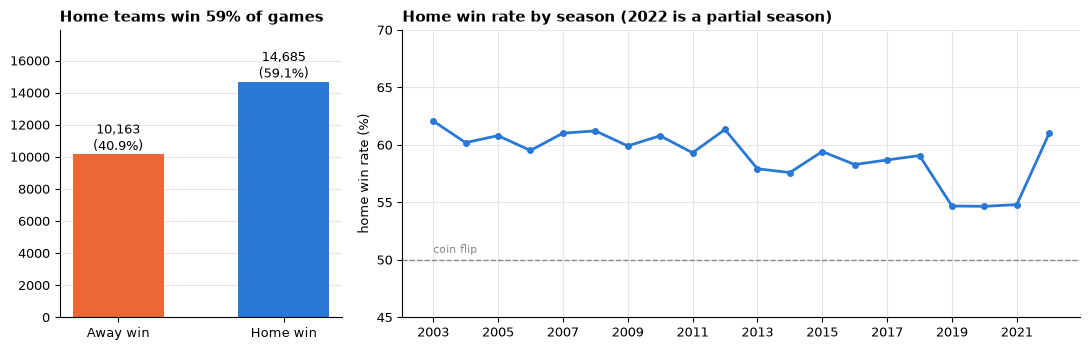

SEASON,2017,2018,2019,2020,2021,2022
home win % (2017-2022),58.7,59.1,54.7,54.7,54.8,61.0


In [16]:
counts = g["HOME_TEAM_WINS"].value_counts().sort_index()
by_season = g.groupby("SEASON")["HOME_TEAM_WINS"].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2.4]})
ax[0].bar(["Away win", "Home win"], counts.values, color=[ORANGE, BLUE], width=0.55)
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}\n({v / len(g):.1%})", ha="center", va="bottom", fontsize=9)
ax[0].set_ylim(0, counts.max() * 1.22); ax[0].grid(axis="x")
ax[0].set_title(f"Home teams win {counts[1] / len(g):.0%} of games")

ax[1].plot(by_season.index, by_season.values, color=BLUE, lw=2, marker="o", ms=4)
ax[1].axhline(50, color=GRAY, ls="--", lw=1); ax[1].text(by_season.index[0], 50.6, "coin flip", color=GRAY, fontsize=8)
ax[1].set_ylim(45, 70); ax[1].set_ylabel("home win rate (%)"); ax[1].set_xticks(by_season.index[::2])
ax[1].set_title("Home win rate by season (2022 is a partial season)")
plt.tight_layout(); plt.show()
by_season.round(1).loc[2017:2022].to_frame("home win % (2017-2022)").T

### 4.2 Home advantage by team

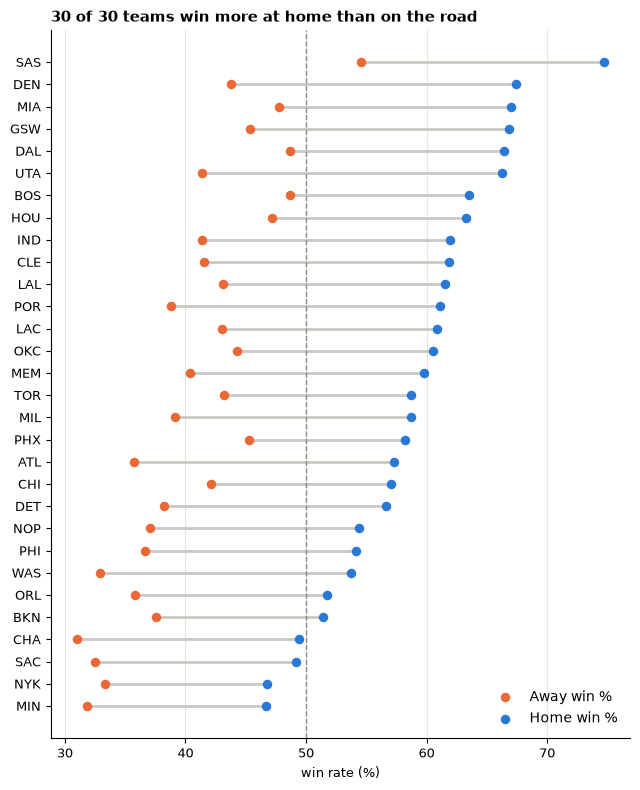

In [17]:
abbr = raw["teams"].set_index("TEAM_ID")["ABBREVIATION"]
rates = (tg.groupby(["TEAM_ID", "IS_HOME"])["WIN"].mean().unstack() * 100).rename(columns={1: "home", 0: "away"})
rates["team"] = rates.index.map(abbr)
rates = rates.sort_values("home").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(6.5, 8))
ypos = range(len(rates))
ax.hlines(ypos, rates["away"], rates["home"], color="#c9c8c2", lw=2)
ax.scatter(rates["away"], ypos, color=ORANGE, s=34, label="Away win %", zorder=3)
ax.scatter(rates["home"], ypos, color=BLUE, s=34, label="Home win %", zorder=3)
ax.axvline(50, color=GRAY, ls="--", lw=1)
ax.set_yticks(list(ypos)); ax.set_yticklabels(rates["team"]); ax.grid(axis="y")
ax.set_xlabel("win rate (%)"); ax.legend(loc="lower right")
ax.set_title(f"{int((rates['home'] > rates['away']).sum())} of {len(rates)} teams win more at home than on the road")
plt.tight_layout(); plt.show()

### 4.3 Scoring over time and home vs away box scores

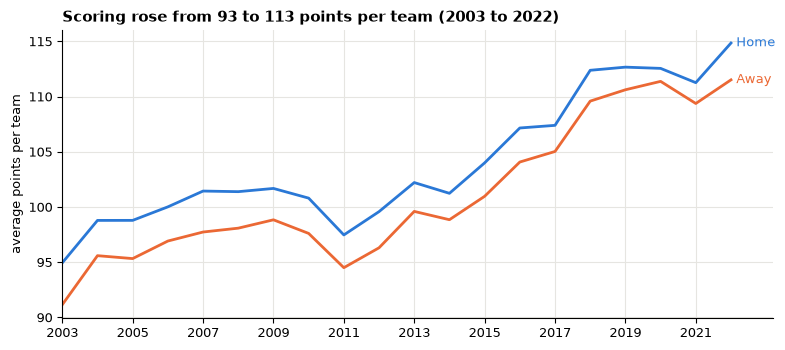

In [18]:
pts = g.groupby("SEASON")[["PTS_home", "PTS_away"]].mean()
overall = tg.groupby("SEASON")["PTS"].mean()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(pts.index, pts["PTS_home"], color=BLUE, lw=2, label="Home")
ax.plot(pts.index, pts["PTS_away"], color=ORANGE, lw=2, label="Away")
ax.text(pts.index[-1] + 0.15, pts["PTS_home"].iloc[-1], "Home", color=BLUE, va="center", fontsize=9)
ax.text(pts.index[-1] + 0.15, pts["PTS_away"].iloc[-1], "Away", color=ORANGE, va="center", fontsize=9)
ax.set_xlim(pts.index[0], pts.index[-1] + 1.2); ax.set_ylabel("average points per team")
ax.set_xticks(range(2003, 2023, 2))
ax.set_title(f"Scoring rose from {overall.iloc[0]:.0f} to {overall.iloc[-1]:.0f} points per team (2003 to 2022)")
plt.tight_layout(); plt.show()

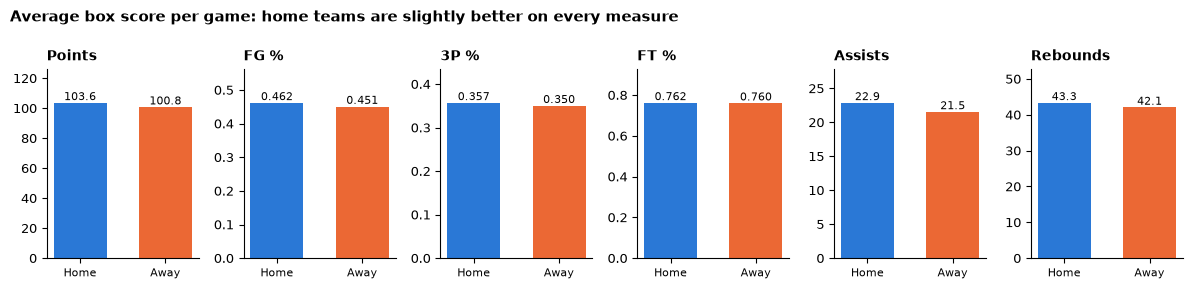

In [19]:
spec = [("Points", "PTS", "{:.1f}"), ("FG %", "FG_PCT", "{:.3f}"), ("3P %", "FG3_PCT", "{:.3f}"),
        ("FT %", "FT_PCT", "{:.3f}"), ("Assists", "AST", "{:.1f}"), ("Rebounds", "REB", "{:.1f}")]
fig, axes = plt.subplots(1, 6, figsize=(12, 2.9))
for ax, (label, s, fmt) in zip(axes, spec):
    vals = [g[f"{s}_home"].mean(), g[f"{s}_away"].mean()]
    ax.bar(["Home", "Away"], vals, color=[BLUE, ORANGE], width=0.62)
    for i, v in enumerate(vals):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, max(vals) * 1.22); ax.set_title(label, fontsize=10); ax.grid(False); ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Average box score per game: home teams are slightly better on every measure", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

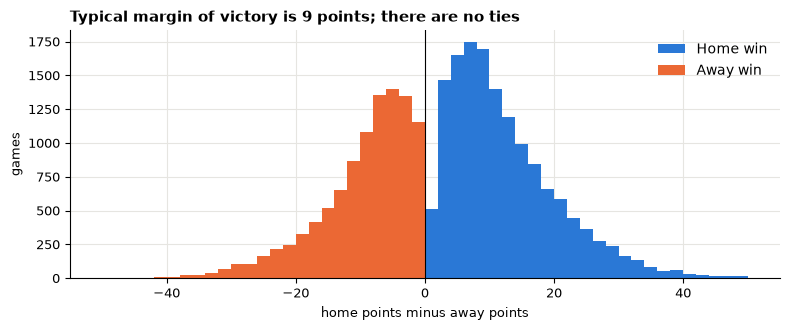

In [20]:
margin = g["PTS_home"] - g["PTS_away"]
bins = np.arange(-50, 51, 2)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(margin[margin > 0], bins=bins, color=BLUE, label="Home win")
ax.hist(margin[margin < 0], bins=bins, color=ORANGE, label="Away win")
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("home points minus away points"); ax.set_ylabel("games")
ax.legend()
ax.set_title(f"Typical margin of victory is {margin.abs().median():.0f} points; there are no ties")
plt.tight_layout(); plt.show()

### 4.4 Do pre-game signals relate to winning? (training seasons only)

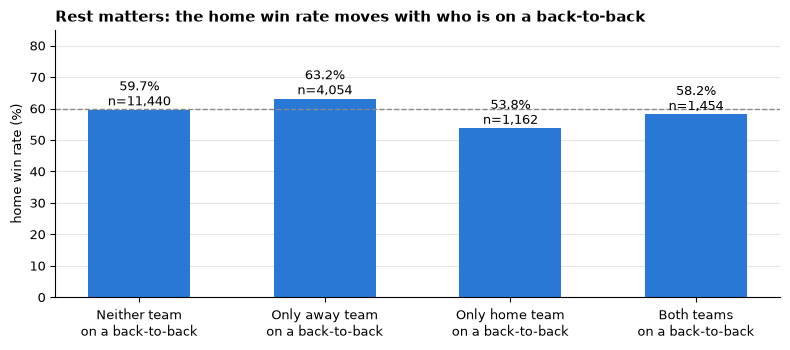

In [21]:
b2b = train.groupby(["HOME_BACK_TO_BACK", "AWAY_BACK_TO_BACK"])["HOME_TEAM_WINS"].agg(["mean", "size"])
names = {(0, 0): "Neither team\non a back-to-back", (1, 0): "Only home team\non a back-to-back",
         (0, 1): "Only away team\non a back-to-back", (1, 1): "Both teams\non a back-to-back"}
b2b_labels = [names[k] for k in b2b.index]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(b2b_labels, b2b["mean"] * 100, color=BLUE, width=0.55)
for i, (m_, n_) in enumerate(zip(b2b["mean"], b2b["size"])):
    ax.text(i, m_ * 100, f"{m_:.1%}\nn={n_:,}", ha="center", va="bottom", fontsize=9)
ax.axhline(train["HOME_TEAM_WINS"].mean() * 100, color=GRAY, ls="--", lw=1)
ax.set_ylim(0, 85); ax.set_ylabel("home win rate (%)"); ax.grid(axis="x")
ax.set_title("Rest matters: the home win rate moves with who is on a back-to-back")
plt.tight_layout(); plt.show()

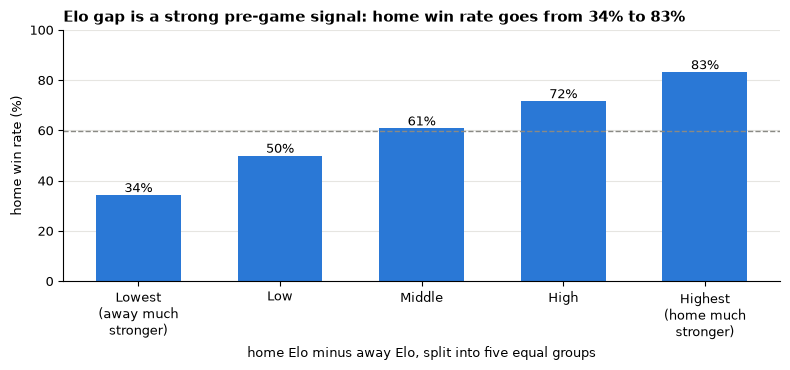

In [22]:
q = pd.qcut(train["DIFF_ELO"], 5)
elo_q = train.groupby(q, observed=True)["HOME_TEAM_WINS"].mean() * 100
labels = ["Lowest\n(away much\nstronger)", "Low", "Middle", "High", "Highest\n(home much\nstronger)"]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(labels, elo_q.values, color=BLUE, width=0.6)
for i, v in enumerate(elo_q.values):
    ax.text(i, v, f"{v:.0f}%", ha="center", va="bottom", fontsize=9)
ax.axhline(train["HOME_TEAM_WINS"].mean() * 100, color=GRAY, ls="--", lw=1)
ax.set_ylim(0, 100); ax.set_ylabel("home win rate (%)"); ax.set_xlabel("home Elo minus away Elo, split into five equal groups"); ax.grid(axis="x")
ax.set_title(f"Elo gap is a strong pre-game signal: home win rate goes from {elo_q.iloc[0]:.0f}% to {elo_q.iloc[-1]:.0f}%")
plt.tight_layout(); plt.show()

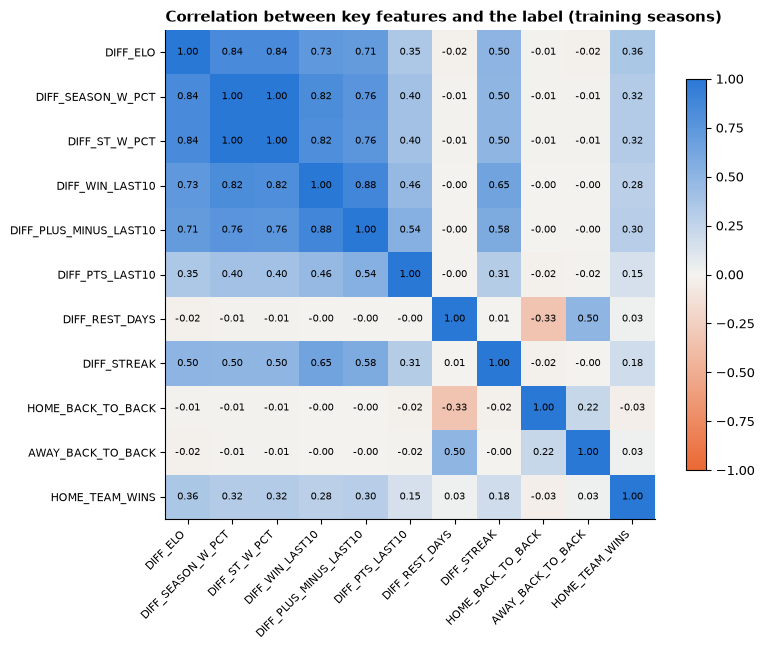

In [23]:
cols = ["DIFF_ELO", "DIFF_SEASON_W_PCT", "DIFF_ST_W_PCT", "DIFF_WIN_LAST10", "DIFF_PLUS_MINUS_LAST10",
        "DIFF_PTS_LAST10", "DIFF_REST_DAYS", "DIFF_STREAK", "HOME_BACK_TO_BACK", "AWAY_BACK_TO_BACK", "HOME_TEAM_WINS"]
cm = train[cols].corr()
cmap = LinearSegmentedColormap.from_list("div", [ORANGE, "#f4f3f0", BLUE])
fig, ax = plt.subplots(figsize=(8.2, 6.6))
im = ax.imshow(cm.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8); ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Correlation between key features and the label (training seasons)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

### 4.5 Data quality: missing values and leakage

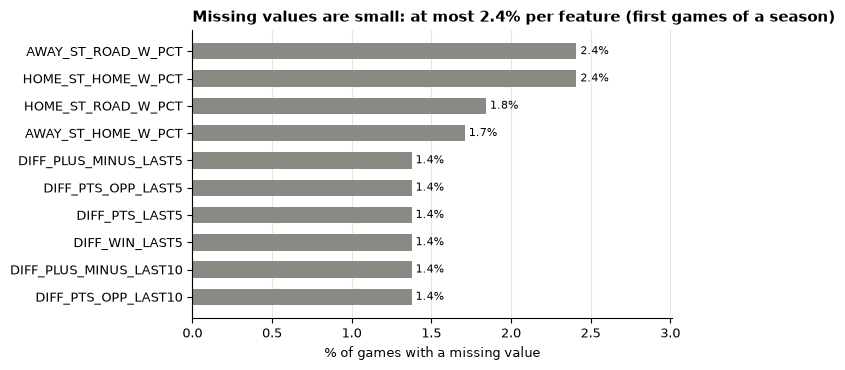

In [24]:
miss = data[feature_cols].isna().mean().mul(100).sort_values(ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(miss.index, miss.values, color=GRAY, height=0.6)
for i, v in enumerate(miss.values):
    ax.text(v, i, f" {v:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, miss.max() * 1.25); ax.grid(axis="y"); ax.set_xlabel("% of games with a missing value")
ax.set_title(f"Missing values are small: at most {miss.max():.1f}% per feature (first games of a season)")
plt.tight_layout(); plt.show()

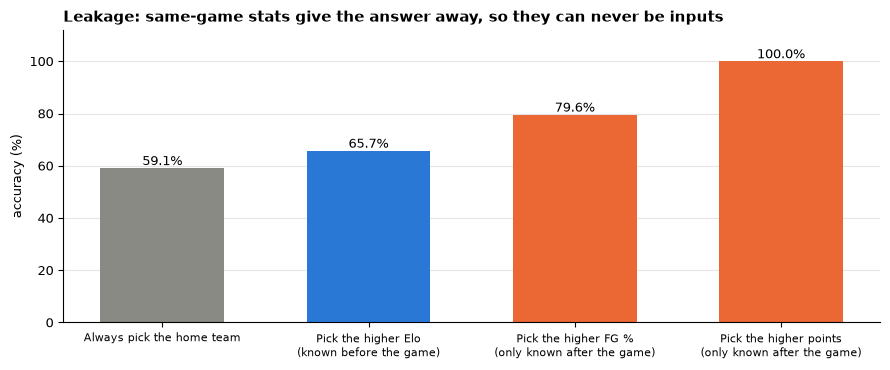

In [25]:
acc = {
    "Always pick the home team": (g["HOME_TEAM_WINS"] == 1).mean(),
    "Pick the higher Elo\n(known before the game)": ((elo["ELO_PROB_HOME"].reindex(g["GAME_ID"]).to_numpy() >= 0.5) == g["HOME_TEAM_WINS"].to_numpy()).mean(),
    "Pick the higher FG %\n(only known after the game)": ((g["FG_PCT_home"] > g["FG_PCT_away"]) == g["HOME_TEAM_WINS"]).mean(),
    "Pick the higher points\n(only known after the game)": ((g["PTS_home"] > g["PTS_away"]) == g["HOME_TEAM_WINS"]).mean(),
}
colors = [GRAY, BLUE, ORANGE, ORANGE]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(list(acc), [v * 100 for v in acc.values()], color=colors, width=0.6)
for i, v in enumerate(acc.values()):
    ax.text(i, v * 100, f"{v:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 112); ax.set_ylabel("accuracy (%)"); ax.grid(axis="x"); ax.tick_params(axis="x", labelsize=8)
ax.set_title("Leakage: same-game stats give the answer away, so they can never be inputs")
plt.tight_layout(); plt.show()

### 4.6 What the EDA tells us
- **Target:** home teams win 59.1% of games, so 59% is the number to beat. The home edge dropped to about 55% in 2019-2021 (COVID, empty arenas, the bubble) and is back at 61% in the partial 2022 season. Our test set (2019-2022) mixes both.
- **Home advantage is universal:** all 30 teams win more at home than on the road.
- **Era drift:** points per team rose from about 93 (2003) to 113 (2022). We use home-minus-away *differences* so a feature means the same thing in every era.
- **Rest matters a little:** the home team wins 53.8% when only it is on a back-to-back, versus 59.7% when neither is and 63.2% when only the visitor is.
- **Elo is a strong signal:** the home win rate rises from 34% (lowest Elo-gap group) to 83% (highest). It has the largest correlation with the label (0.36).
- **Redundant features:** `DIFF_SEASON_W_PCT` and `DIFF_ST_W_PCT` are correlated at 1.00 (same information from two sources), and several form features are correlated at 0.7 to 0.9. This matters for linear models and for reading feature importance later.
- **Missing values:** at most 2.4% per feature, all from the first games of a season. They are filled with the training median when we build the models.
- **Leakage:** picking the higher-scoring team is right 100% of the time and the higher FG% 79.6%, but both are only known after the game. The pre-game Elo pick gets 65.7% (all seasons).